# 03b: Transformer espacial na validação (task 23)

**Pergunta:** o grafo geográfico não ajudou o STGCN (`03_modelos`). Isso quer dizer que não existe dependência útil entre municípios, ou que o grafo dos 5 vizinhos mais próximos é o grafo errado?

Para responder, trocamos o grafo fixo por **atenção**: um Transformer em que cada município é um token e decide, a cada janela, quanto olhar para cada um dos outros 78. É a ideia de modelos recentes de séries espaço-temporais, como o iTransformer (2024) e o STAEformer (2023), numa versão pequena:

| Peça | Como é |
| --- | --- |
| Token | as 4 semanas × 4 variáveis do município, por uma camada linear (d = 32), mais um embedding aprendido do município |
| Atenção | 2 camadas pre-norm, 4 cabeças, MLP 2d, dropout 0,2 |
| Cabeça | linear do token final para as 4 semanas previstas |
| Ablação | a mesma rede com uma máscara que deixa cada município olhar só para si (o "A = I" do Transformer) |

O protocolo de treino é **o mesmo do STGCN final** (AdamW, warmup + cosseno, Huber em `log1p`, 920 passos, lote 32, clip 5, 3 seeds). Assim, a diferença para o STGCN é só a arquitetura. Só o η foi escolhido de novo, pela validação. Os resultados vêm de:

```
python -m dengue.varredura configs/transformer/etapa1.yaml --resultados results/transformer   # η, 1 seed
python -m dengue.varredura configs/transformer/etapa2.yaml --resultados results/transformer   # 3 finalistas, 3 seeds
python -m dengue.experimento configs/transformer/sem_atencao.yaml --resultados results/transformer
python -m dengue.atencao                                                                      # mapa de atenção
```

Este notebook só lê os resultados. O teste não aparece aqui: ele está no `05_resultado_final`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from dengue import atencao, dados

RES = dados.RAIZ / 'results'
tr = pd.read_csv(RES / 'transformer' / 'experimentos.csv')
mapa = pd.read_csv(RES / 'transformer' / 'atencao_validacao.csv', index_col='municipio')
janelas = pd.read_csv(RES / 'transformer' / 'atencao_janelas.csv', parse_dates=['data'])

# Referências do STGCN e do LSTM: só as linhas de validação (mesmas seeds e protocolo)
ref = pd.read_csv(RES / 'teste_final.csv').query("particao == 'validacao'")
metricas = ['mae', 'rmse', 'mae_surto', 'mae_calmaria']
LR = 0.01  # η congelado em configs/transformer.yaml

### Pergunta 1: qual η treina melhor o Transformer?

Etapa 1: grade de η com uma seed. Etapa 2: os três melhores com 3 seeds. O critério é o mesmo da task 19, a menor perda média na validação.

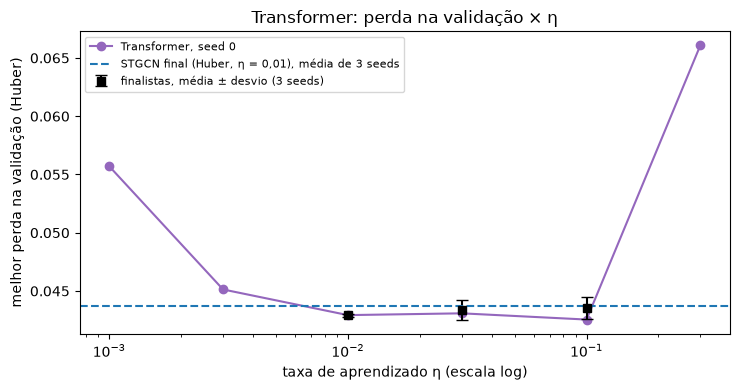

,mean,std
lr,,
0.01,0.0429,0.0002
0.03,0.0433,0.0009
0.10,0.0435,0.0009


In [2]:
com = tr[tr['atencao'] & (tr['etapa'] != 'ablacao')]
s0 = com[com['seed'] == 0].sort_values('lr')
finalistas = com.groupby('lr').filter(lambda g: len(g) == 3).groupby('lr')['melhor_val_loss']
stgcn_huber = pd.read_csv(RES / 'perdas' / 'experimentos.csv').query("perda == 'huber'")

fig, ax = plt.subplots(figsize=(7.5, 4))
ax.plot(s0['lr'], s0['melhor_val_loss'], marker='o', color='tab:purple', label='Transformer, seed 0')
ax.errorbar(finalistas.mean().index, finalistas.mean(), yerr=finalistas.std(), fmt='s', capsize=4,
            color='k', label='finalistas, média ± desvio (3 seeds)')
ax.axhline(stgcn_huber['melhor_val_loss'].mean(), color='tab:blue', ls='--',
           label='STGCN final (Huber, η = 0,01), média de 3 seeds')
ax.set_xscale('log')
ax.set(xlabel='taxa de aprendizado η (escala log)', ylabel='melhor perda na validação (Huber)',
       title='Transformer: perda na validação × η')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()
finalistas.agg(['mean', 'std']).round(4)

**Conclusão:** o Transformer tem o mesmo comportamento do STGCN na task 19: um **vale largo e plano** entre η = 0,01 e 0,1, com um penhasco logo depois (em η = 0,3, a perda sobe 55%). Com 3 seeds, os três finalistas ficam a menos de 0,001 um do outro. η = 0,01 tem a menor média (0,0429) e o menor desvio (0,0002), e foi o congelado. É o mesmo η do STGCN final, então os dois modelos têm protocolo idêntico.

### Pergunta 2: na validação, o Transformer supera o STGCN? A atenção ajuda?

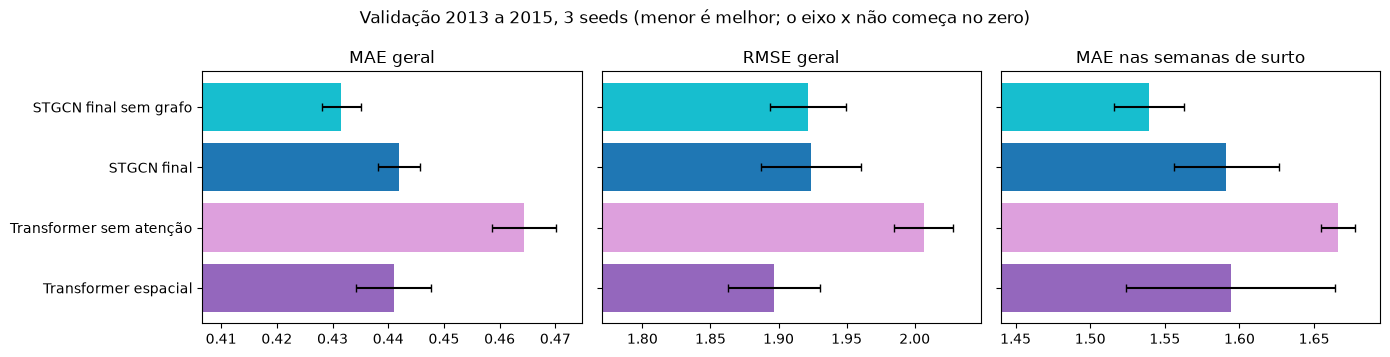

,mae,rmse,mae_surto,mae_calmaria
STGCN final sem grafo,0.432 ± 0.003,1.922 ± 0.028,1.539 ± 0.023,0.229 ± 0.004
STGCN final,0.442 ± 0.004,1.924 ± 0.037,1.591 ± 0.035,0.232 ± 0.008
Transformer sem atenção,0.464 ± 0.006,2.007 ± 0.022,1.666 ± 0.012,0.245 ± 0.006
Transformer espacial,0.441 ± 0.007,1.897 ± 0.034,1.594 ± 0.070,0.231 ± 0.005


In [3]:
linhas = {
    'STGCN final sem grafo': ref[ref['modelo'] == 'stgcn_sem_grafo'],
    'STGCN final': ref[ref['modelo'] == 'stgcn_final'],
    'Transformer sem atenção': tr[(tr['etapa'] == 'ablacao')],
    'Transformer espacial': tr[tr['atencao'] & (tr['lr'] == LR) & (tr['etapa'] != 'ablacao')],
}
cores = ['tab:cyan', 'tab:blue', 'plum', 'tab:purple']
media = pd.DataFrame({k: v[metricas].mean() for k, v in linhas.items()}).T
desvio = pd.DataFrame({k: v[metricas].std() for k, v in linhas.items()}).T
assert all(len(v) == 3 for v in linhas.values())  # 3 seeds em cada

fig, eixos = plt.subplots(1, 3, figsize=(14, 3.6), sharey=True)
titulos = {'mae': 'MAE geral', 'rmse': 'RMSE geral', 'mae_surto': 'MAE nas semanas de surto'}
for ax, (m, titulo) in zip(eixos, titulos.items()):
    ax.barh(media.index, media[m], xerr=desvio[m], capsize=3, color=cores)
    ax.set_title(titulo)
    lo = (media[m] - desvio[m]).min()
    ax.set_xlim(lo * 0.95, (media[m] + desvio[m]).max() * 1.01)
eixos[0].invert_yaxis()
fig.suptitle('Validação 2013 a 2015, 3 seeds (menor é melhor; o eixo x não começa no zero)')
plt.tight_layout()
plt.show()
pd.DataFrame({m: [f'{media.loc[i, m]:.3f} ± {desvio.loc[i, m]:.3f}' for i in media.index]
              for m in metricas}, index=media.index)

**Conclusão:**
- **A atenção ajuda o Transformer:** com ela, o MAE cai de 0,464 para 0,441 (−5%), o RMSE de 2,01 para 1,90 (−5%) e o MAE em surto de 1,67 para 1,59. Diferente do grafo geo no STGCN, a troca de informação entre municípios aqui tem efeito claro, bem acima do desvio entre seeds.
- **Mas o Transformer completo só empata com o STGCN final** (MAE 0,441 contra 0,442; RMSE 1,90 contra 1,92), e o STGCN sem grafo continua o melhor (0,432).
- O Transformer sem atenção é o pior dos quatro. Ele trata as 4 semanas como um vetor achatado, sem a convolução temporal do STGCN. A atenção compensa essa perda, mas não passa à frente. Ou seja: **existe sinal útil nos outros municípios**, e a atenção acha esse sinal, mas o ganho é do mesmo tamanho do que a convolução temporal já extrai do passado do próprio município.

### Pergunta 3: para quem o Transformer olha? A atenção redescobre a vizinhança geográfica?

O mapa é a atenção média nas 149 janelas da validação (média das 2 camadas e das 4 cabeças), do modelo congelado com seed 0. A linha i diz quanto o município i olhou para cada município j.

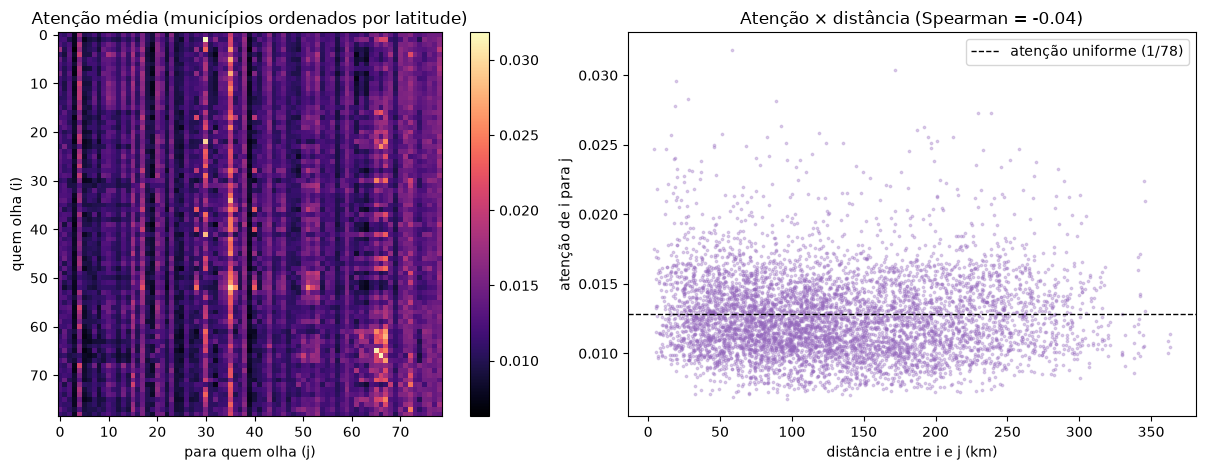

Da atenção para os outros municípios, 8.5% cai nos vizinhos do k-NN (o acaso daria 7.9%). Atenção em si mesmo: 1.5%.
Atenção recebida por município: máximo 1.70, mínimo 0.64 (média 1).


In [4]:
df = dados.carregar_tabela()
dist = atencao.distancias_do_projeto(df)
m = mapa.to_numpy()
resumo = atencao.comparar_com_grafo(m, dist)

# ordena os municípios pela latitude, para vizinhos ficarem perto no eixo
coord = df.groupby('municipio')[['latitude', 'longitude']].first().loc[dados.municipios(df)]
ordem = np.argsort(coord['latitude'].to_numpy())

fig, eixos = plt.subplots(1, 2, figsize=(13, 4.8))
im = eixos[0].imshow(m[np.ix_(ordem, ordem)], cmap='magma')
eixos[0].set(title='Atenção média (municípios ordenados por latitude)', xlabel='para quem olha (j)',
             ylabel='quem olha (i)')
fig.colorbar(im, ax=eixos[0], fraction=0.046)

fora = ~np.eye(len(m), dtype=bool)
eixos[1].scatter(dist[fora], m[fora], s=3, alpha=0.3, color='tab:purple')
eixos[1].axhline(1 / (len(m) - 1), color='k', ls='--', lw=1, label='atenção uniforme (1/78)')
eixos[1].set(xlabel='distância entre i e j (km)', ylabel='atenção de i para j',
             title=f"Atenção × distância (Spearman = {resumo['corr_distancia']:.2f})")
eixos[1].legend()
plt.tight_layout()
plt.show()
recebida = m.sum(0)  # quanto cada município recebe de todos (média 1)
print(f"Da atenção para os outros municípios, {resumo['fracao_vizinhos']:.1%} cai nos vizinhos do k-NN "
      f"(o acaso daria {resumo['fracao_esperada']:.1%}). Atenção em si mesmo: {resumo['atencao_propria']:.1%}.")
print(f"Atenção recebida por município: máximo {recebida.max():.2f}, mínimo {recebida.min():.2f} (média 1).")

**Conclusão:** **não**. A atenção aprendida ignora a geografia:
- dos pesos que vão para os outros municípios, 8,5% caem nos vizinhos do k-NN, quase o mesmo que o acaso (7,9%);
- a correlação entre atenção e distância é praticamente zero (Spearman −0,04);
- o padrão do mapa é de **listras verticais**: alguns municípios recebem mais atenção de **todos** os outros (até 1,7 vez a média), estejam perto ou longe. Não há blocos na diagonal, que seriam o sinal de vizinhanças regionais.

Isso é coerente com o que o resto do projeto mostrou. A dependência útil entre municípios **não é local**: o modelo não precisa saber o que acontece no vizinho, e sim num resumo do **estado como um todo**, montado a partir de alguns municípios "sensores" que valem para todo mundo. Por isso o grafo dos vizinhos geográficos não ajudou o STGCN: ele só deixa a informação andar dois saltos, e o sinal que importa é global.

### Pergunta 4: a atenção é sempre larga, ou muda com a situação da epidemia?

Uma média de mapas concentrados pode parecer uniforme se cada janela olha para um lugar diferente. Por isso medimos a **entropia relativa** janela a janela: 1 = atenção uniforme, 0 = olha para um município só.

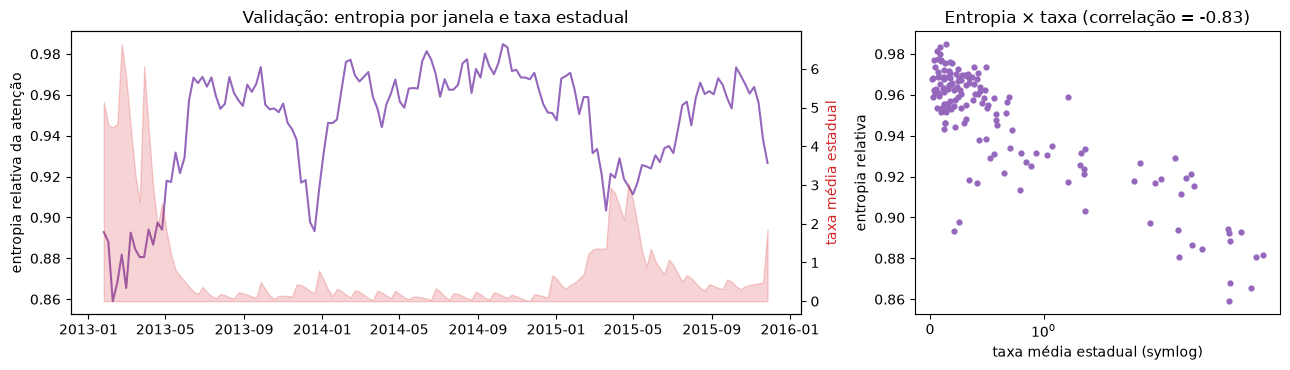

count    149.000
mean       0.946
std        0.028
min        0.859
25%        0.930
50%        0.957
75%        0.967
max        0.985
Name: entropia, dtype: float64

In [5]:
fig, eixos = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw={'width_ratios': [2, 1]})
ax = eixos[0]
ax.plot(janelas['data'], janelas['entropia'], color='tab:purple')
ax.set(ylabel='entropia relativa da atenção', title='Validação: entropia por janela e taxa estadual')
ax2 = ax.twinx()
ax2.fill_between(janelas['data'], janelas['taxa_media'], color='tab:red', alpha=0.2)
ax2.set_ylabel('taxa média estadual', color='tab:red')

corr = janelas['entropia'].corr(janelas['taxa_media'])
eixos[1].scatter(janelas['taxa_media'], janelas['entropia'], s=12, color='tab:purple')
eixos[1].set(xscale='symlog', xlabel='taxa média estadual (symlog)', ylabel='entropia relativa',
             title=f'Entropia × taxa (correlação = {corr:.2f})')
plt.tight_layout()
plt.show()
janelas['entropia'].describe().round(3)

**Conclusão:** a atenção é larga em todas as janelas (entropia entre 0,86 e 0,99, mediana 0,96), então não é uma média de mapas concentrados. Mas ela **fica mais seletiva nos surtos**: a correlação entre entropia e taxa estadual é −0,83. Nos picos de 2013 e 2015, a entropia cai, e cada município passa a olhar mais para alguns poucos, em vez de fazer uma média geral.

### Resumo

- O Transformer espacial, treinado com o mesmo protocolo do STGCN final, **empata com ele na validação** (MAE 0,441 contra 0,442) e fica atrás do STGCN sem grafo (0,432).
- Ao contrário do grafo geo, **a atenção entre municípios ajuda** (−5% no MAE contra a mesma rede sem atenção). Existe sinal útil nos outros municípios.
- Esse sinal **não é geográfico**: a atenção ignora a distância e se espalha pelo estado inteiro, concentrando-se um pouco mais nos surtos. Isso explica por que o k-NN geográfico não ajudou o STGCN.
- A configuração ficou congelada em `configs/transformer.yaml` com η = 0,01, antes da avaliação no teste (`05_resultado_final`).